In [1]:
import pandas as pd
import numpy as np
import os
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

In [2]:
ROOT = Path.cwd().parent

DATA_DIR = ROOT / "data"
LABEL_DIR = ROOT / "labels"

print(ROOT)
print(DATA_DIR)
print(LABEL_DIR)

F:\EDAIC-WOZ
F:\EDAIC-WOZ\data
F:\EDAIC-WOZ\labels


In [3]:
train_labels = pd.read_csv(LABEL_DIR / "train_split.csv")
dev_labels   = pd.read_csv(LABEL_DIR / "dev_split.csv")
test_labels  = pd.read_csv(LABEL_DIR / "test_split.csv")

print(train_labels.shape)
print(dev_labels.shape)
print(test_labels.shape)

(163, 6)
(56, 6)
(56, 6)


In [4]:
def get_feature_path(pid, feature_type="eGeMAPS"):
    if feature_type == "eGeMAPS":
        return (
            DATA_DIR
            / f"{pid}_P"
            / "features"
            / f"{pid}_BoAW_openSMILE_2.3.0_eGeMAPS.csv"
        )

    if feature_type == "MFCC":
        return (
            DATA_DIR
            / f"{pid}_P"
            / "features"
            / f"{pid}_BoAW_openSMILE_2.3.0_MFCC.csv"
        )

In [5]:
pid = 300

feature_file = get_feature_path(pid, "eGeMAPS")

df = pd.read_csv(feature_file)

print("Shape:", df.shape)
display(df.head())

Shape: (6484, 102)


,'unknown',0.0,1.4149733999999998,0.0.1,0.0.2,0.0.3,0.0.4,0.0.5,0.0.6,0.0.7,...,0.0.67,0.0.68,0.0.69,0.0.70,0.0.71,0.0.72,0.0.73,1.4313638000000002,0.0.74,0.0.75
0,'unknown',0.1,1.414973,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.462398,0.0,0.0
1,'unknown',0.2,1.414973,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.518514,0.0,0.0
2,'unknown',0.3,1.414973,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.544068,0.0,0.0
3,'unknown',0.4,1.414973,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.544068,0.0,0.0
4,'unknown',0.5,1.414973,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.544068,0.0,0.0


In [6]:
numeric_df = df.select_dtypes(include=np.number)

print(numeric_df.shape)

(6484, 101)


In [7]:
participant_features = numeric_df.mean()

print(participant_features.shape)

(101,)


In [8]:
def extract_egemaps(pid):

    feature_file = get_feature_path(pid, "eGeMAPS")

    df = pd.read_csv(
        feature_file,
        header=None
    )

    # Remove metadata columns only
    acoustic_df = df.iloc[:, 2:]

    return acoustic_df.mean()

In [9]:
features = extract_egemaps(300)

print(features.shape)
print(features.head())

(100,)
2    0.339651
3    0.309486
4    0.098401
5    0.000000
6    0.030742
dtype: float64


In [10]:
rows = []

for _, row in train_labels.iterrows():

    pid = row["Participant_ID"]

    try:
        features = extract_egemaps(pid)

        feature_dict = features.to_dict()

        feature_dict["Participant_ID"] = pid
        feature_dict["PHQ_Binary"] = row["PHQ_Binary"]
        feature_dict["PHQ_Score"] = row["PHQ_Score"]

        rows.append(feature_dict)

    except Exception as e:
        print(pid, e)

In [11]:
dataset = pd.DataFrame(rows)

print(dataset.shape)

dataset.head()

(163, 103)


,2,3,4,5,6,7,8,9,10,11,...,95,96,97,98,99,100,101,Participant_ID,PHQ_Binary,PHQ_Score
0,0.431654,0.008801,0.070662,0.003179,0.027842,0.008674,0.063036,0.172168,0.007635,1.226420,...,0.004769,0.036439,0.000000,0.000000,1.301627,0.625192,0.000000,302,0,4
1,0.688838,1.028125,0.041777,0.000000,0.434868,0.151256,0.025126,0.557120,0.003796,0.795972,...,0.010686,0.020555,0.000000,0.000000,1.240207,0.662137,0.003732,303,0,0
2,0.594773,0.658804,0.043229,0.000000,0.336465,0.103073,0.010107,0.303097,0.005749,0.999255,...,0.010145,0.012753,0.000000,0.000000,1.275509,0.773041,0.000000,304,0,6
3,0.019933,0.619588,0.009948,0.003398,0.023531,0.081506,0.002844,0.306944,0.000000,0.032020,...,0.000000,0.022808,0.003079,0.200938,0.051655,0.055726,0.000000,305,0,7
4,0.025780,1.408446,0.044388,0.000000,0.349453,0.106781,0.002917,0.133493,0.000997,0.023163,...,0.000972,0.000000,0.009310,0.237264,0.035164,0.109878,0.000000,307,0,4


In [12]:
dataset["PHQ_Binary"].value_counts()

PHQ_Binary
0    126
1     37
Name: count, dtype: int64

In [13]:
dataset["PHQ_Binary"].value_counts(normalize=True)

PHQ_Binary
0    0.773006
1    0.226994
Name: proportion, dtype: float64

In [14]:
X = dataset.drop(
    columns=[
        "Participant_ID",
        "PHQ_Binary",
        "PHQ_Score"
    ]
)

y = dataset["PHQ_Binary"]

print(X.shape)
print(y.shape)

(163, 100)
(163,)


In [15]:
constant_cols = [
    col for col in X.columns
    if X[col].nunique() <= 1
]

print("Constant columns:", len(constant_cols))

Constant columns: 0


In [16]:
print(X.shape)

(163, 100)


In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [19]:
from sklearn.feature_selection import SelectKBest, f_classif
selector = SelectKBest(
    score_func=f_classif,
    k=5
)

selector.fit(X, y)

selected_features = X.columns[selector.get_support()]

for feature in selected_features:
    print(feature)

12
26
35
57
60


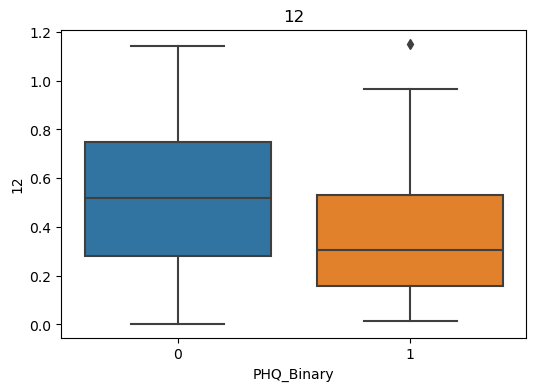

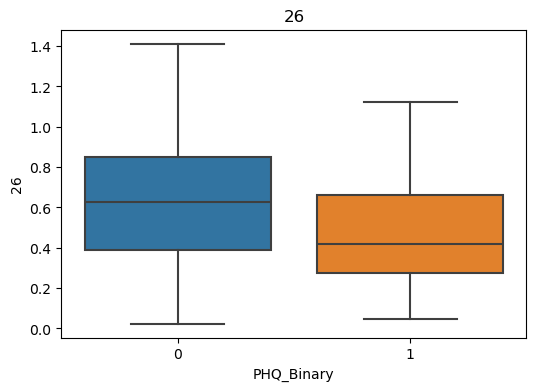

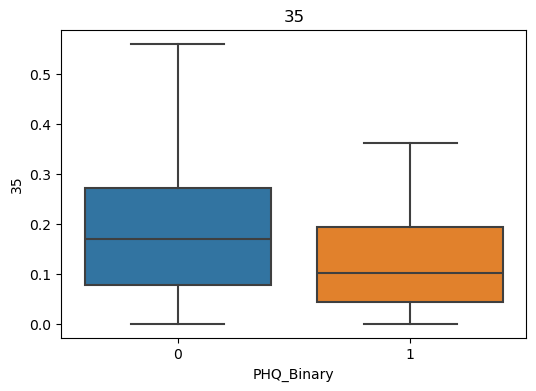

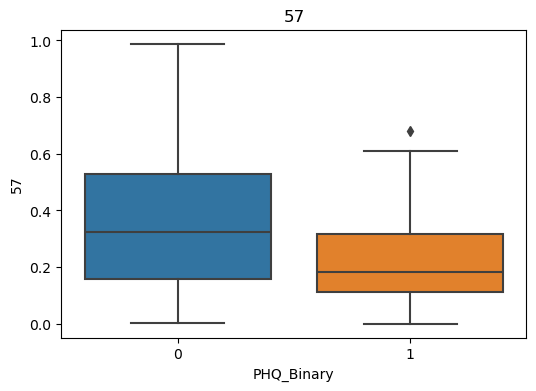

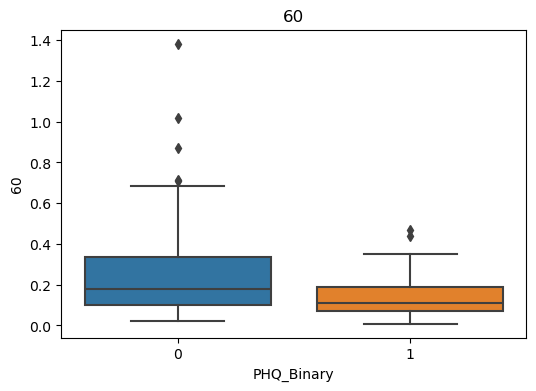

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in selected_features:

    plt.figure(figsize=(6,4))

    sns.boxplot(
        x=dataset["PHQ_Binary"],
        y=dataset[feature]
    )

    plt.title(feature)

    plt.show()

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pipeline = Pipeline([
    ("selector", SelectKBest(f_classif, k=5)),
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        class_weight="balanced",
        max_iter=5000
    ))
])

scores = cross_val_score(
    pipeline,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print(scores.mean())

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

preds = cross_val_predict(
    pipeline,
    X,
    y,
    cv=cv
)

print(classification_report(y, preds))

0.36564835164835163
              precision    recall  f1-score   support

           0       0.82      0.60      0.69       126
           1       0.29      0.57      0.39        37

    accuracy                           0.59       163
   macro avg       0.56      0.58      0.54       163
weighted avg       0.70      0.59      0.62       163



In [71]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn import set_config

set_config(display="diagram")

model = Pipeline([
    ("selector", SelectKBest(
        score_func=f_classif,
        k=5
    )),
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

model



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('selector', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function f_c...00234DC47F420>
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",5
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2'}, default='l2'Specifies the norm used in the penalization. The 'l2'penalty is the standard used in SVC. The 'l1' leads to ``coef_``vectors that are sparse.",'l2'
,"loss loss: {'hinge', 'squared_hinge'}, default='squared_hinge'Specifies the loss function. 'hinge' is the standard SVM loss(used e.g. by the SVC class) while 'squared_hinge' is thesquare of the hinge loss. The combination of ``penalty='l1'``and ``loss='hinge'`` is not supported.",'squared_hinge'


In [73]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print("5-Fold F1 Scores:")
for i, score in enumerate(scores, 1):
    print(f"Fold {i}: {score:.4f}")

print(f"\nMean F1: {scores.mean():.4f}")
print(f"Std F1:  {scores.std():.4f}")

5-Fold F1 Scores:
Fold 1: 0.3200
Fold 2: 0.1538
Fold 3: 0.4615
Fold 4: 0.4762
Fold 5: 0.4167

Mean F1: 0.3656
Std F1:  0.1191
